In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_theme(style="whitegrid")

In [7]:
print("--- Loading Dataset ---")
df = sns.load_dataset("taxis")
print(df.head())
print("-" * 50)

--- Loading Dataset ---
               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upp

In [8]:
print("--- Handling Missing Values ---")
print("Missing values before imputation:")
print(df.isnull().sum())

--- Handling Missing Values ---
Missing values before imputation:
pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [16]:
critical_cols = ["pickup", "dropoff", "pickup_borough", "dropoff_borough"]
df = df.dropna(subset=critical_cols)
num_cols = df.select_dtypes(include=[np.number]).columns
 for col in num_cols:
    if df[col].isnull().sum() > 0:
   df[col] = df[col].fillna(df[col].median())
cat_cols = df.select_dtypes(include=["object", "category"]).columns
for col in cat_cols:
  if df[col].isnull().sum() > 0:
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing values after imputation:")
print(df.isnull().sum())
print("-" * 50)

IndentationError: unindent does not match any outer indentation level (<string>, line 6)

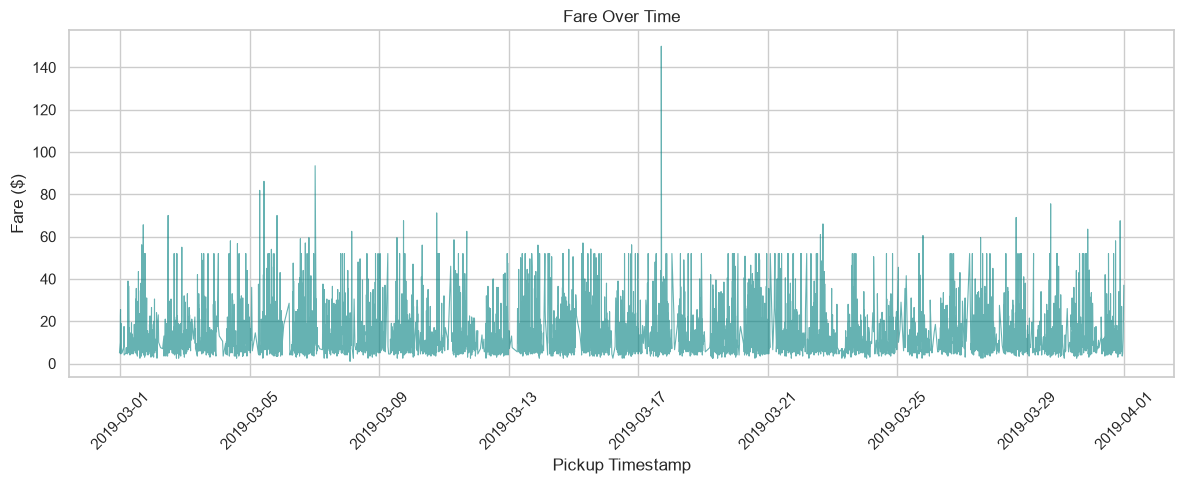

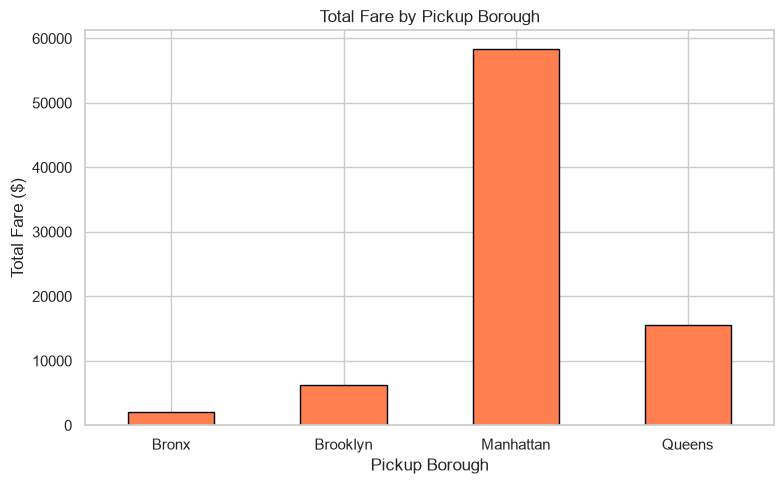

In [17]:
df["pickup"] = pd.to_datetime(df["pickup"])
df_sorted = df.sort_values("pickup")
plt.figure(figsize=(12, 5))
plt.plot(
    df_sorted["pickup"],
    df_sorted["fare"],
    color="teal",
    alpha=0.6,
    linewidth=0.8,
)
plt.title("Fare Over Time")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --- Bar Chart: Total fare for each pickup_borough ---
borough_fare = df.groupby("pickup_borough")["fare"].sum()
plt.figure(figsize=(8, 5))
borough_fare.plot(kind="bar", color="coral", edgecolor="black")
plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

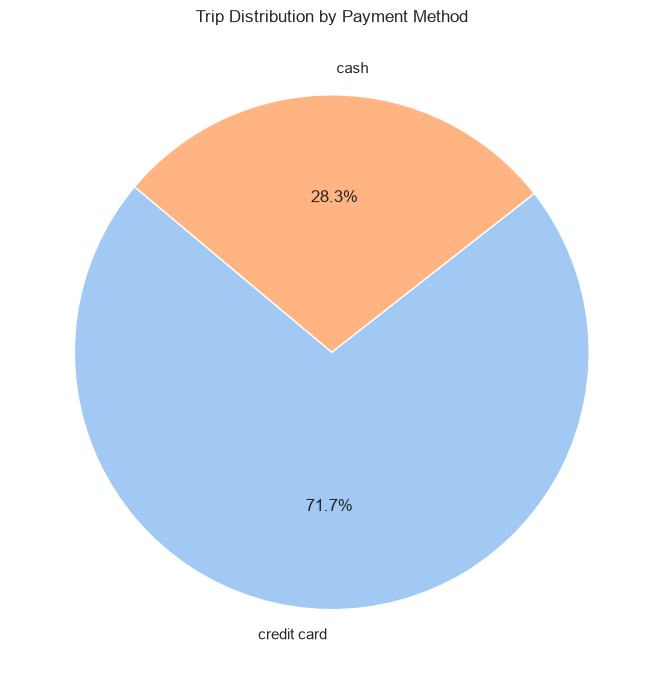

In [18]:
payment_counts = df["payment"].value_counts()
plt.figure(figsize=(7, 7))
plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=sns.color_palette("pastel"),
)
plt.title("Trip Distribution by Payment Method")
plt.tight_layout()
plt.show()

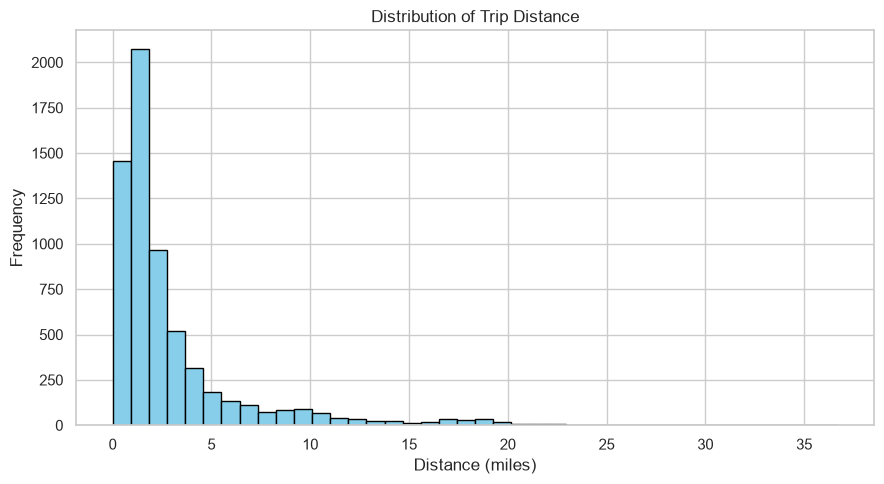

In [19]:
plt.figure(figsize=(9, 5))
plt.hist(df["distance"], bins=40, color="skyblue", edgecolor="black")
plt.title("Distribution of Trip Distance")
plt.xlabel("Distance (miles)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

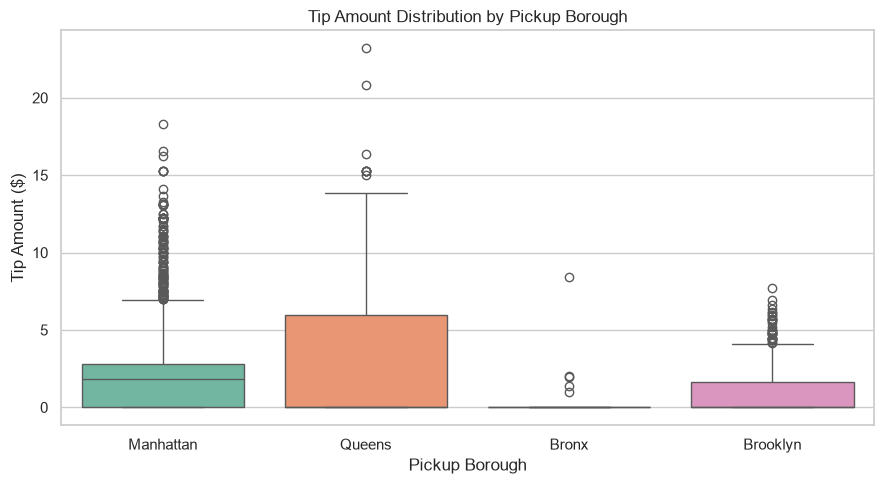

In [20]:
plt.figure(figsize=(9, 5))
sns.boxplot(
    x="pickup_borough",
    y="tip",
    data=df,
    palette="Set2",
    hue="pickup_borough",
    legend=False,
)
plt.title("Tip Amount Distribution by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount ($)")
plt.tight_layout()
plt.show()

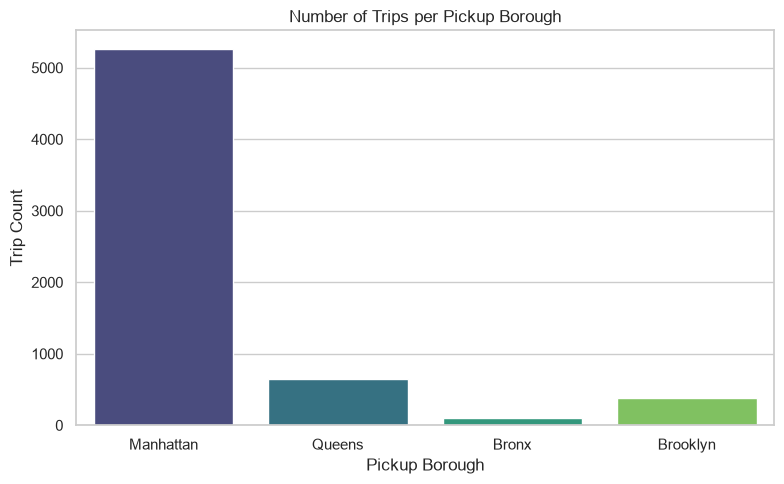

In [21]:
plt.figure(figsize=(8, 5))
sns.countplot(
    x="pickup_borough",
    data=df,
    palette="viridis",
    hue="pickup_borough",
    legend=False,
)
plt.title("Number of Trips per Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Trip Count")
plt.tight_layout()
plt.show()

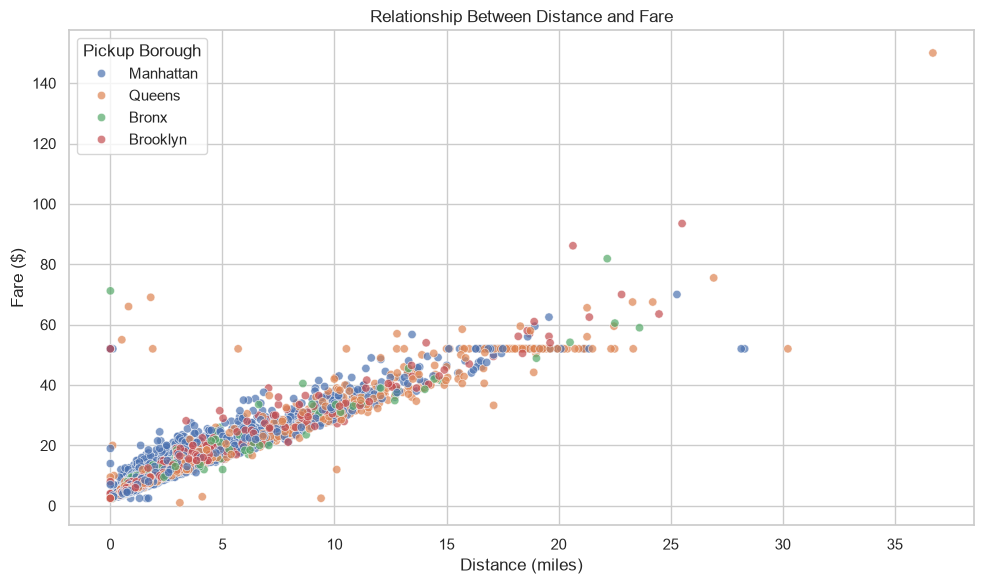

In [22]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x="distance",
    y="fare",
    hue="pickup_borough",
    data=df,
    palette="deep",
    alpha=0.7,
)
plt.title("Relationship Between Distance and Fare")
plt.xlabel("Distance (miles)")
plt.ylabel("Fare ($)")
plt.legend(title="Pickup Borough")
plt.tight_layout()
plt.show()

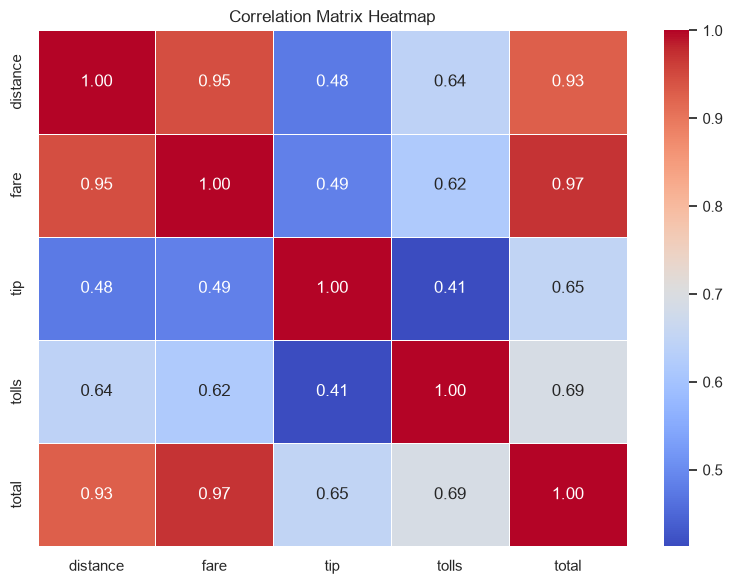

In [23]:
plt.figure(figsize=(8, 6))
num_vars = ["distance", "fare", "tip", "tolls", "total"]
corr_matrix = df[num_vars].corr()
sns.heatmap(
    corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5
)
plt.title("Correlation Matrix Heatmap")
plt.tight_layout()
plt.show()

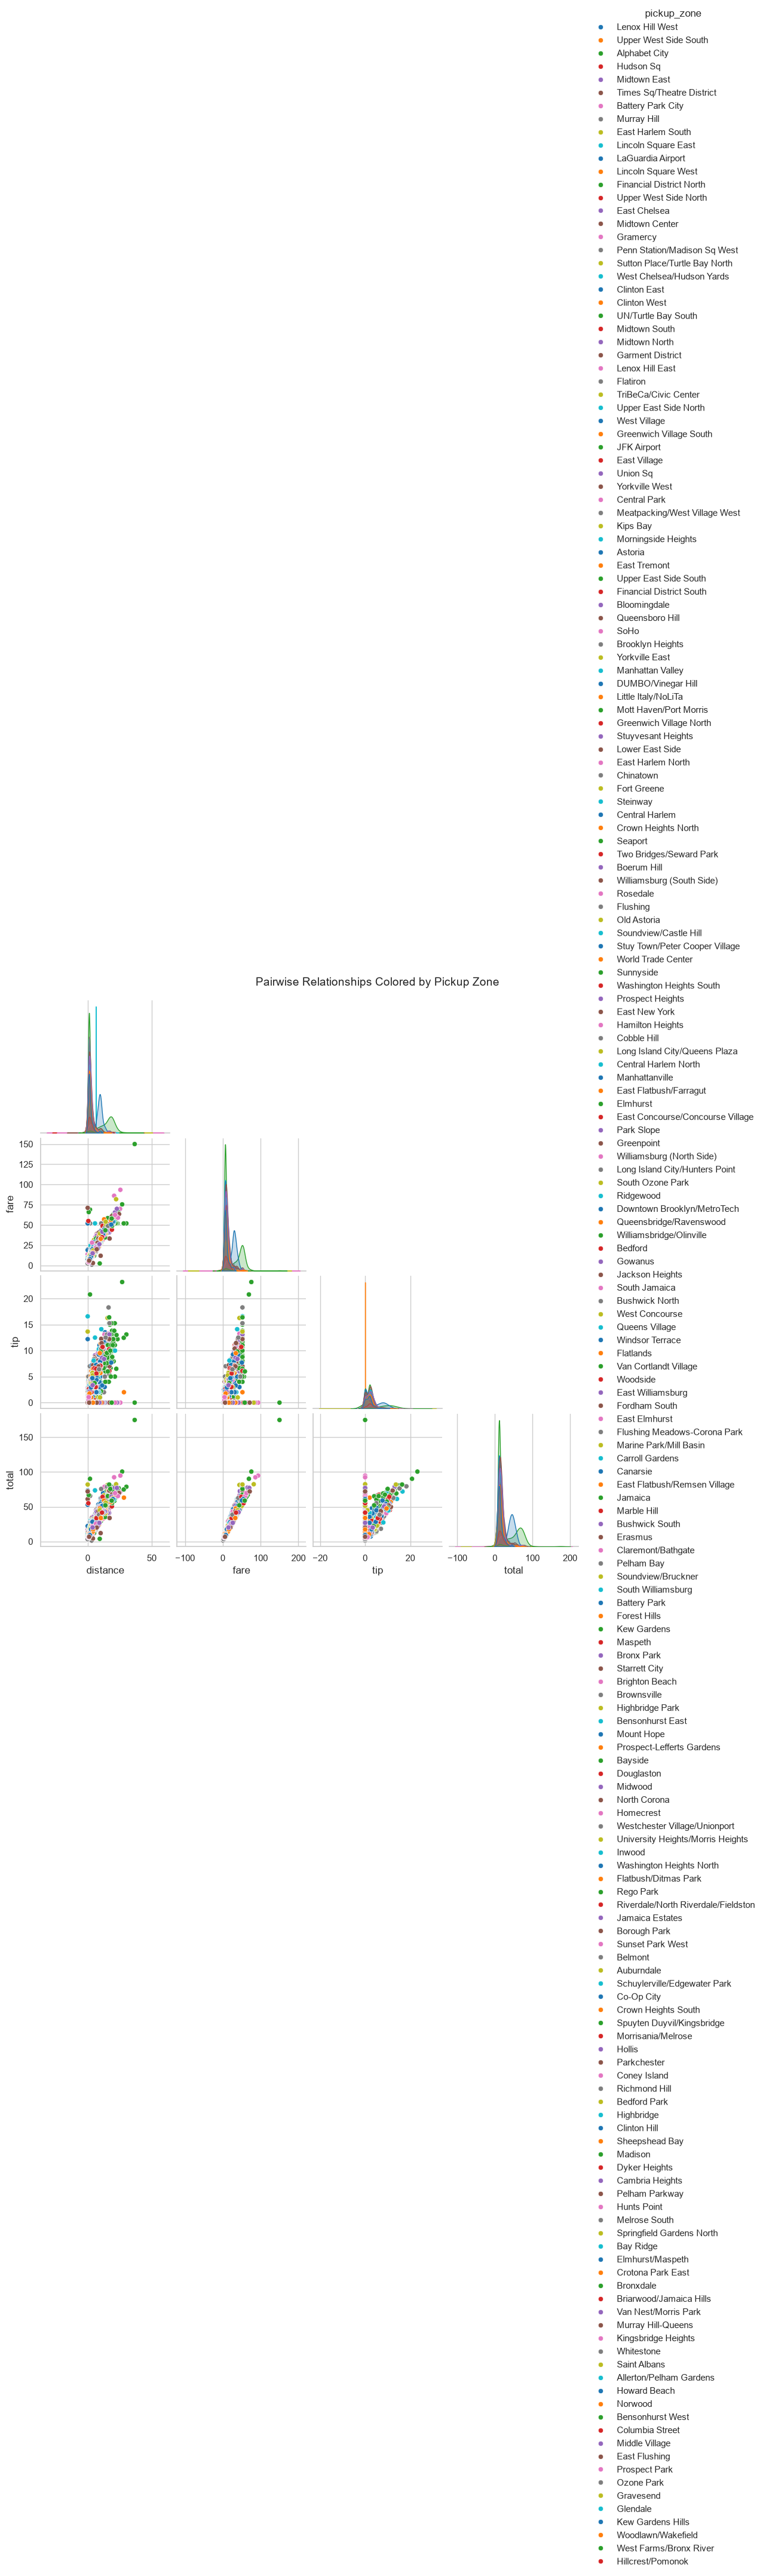

In [29]:
pair_cols = ["distance", "fare", "tip", "total", "pickup_zone"]
sns.pairplot(
    df[pair_cols].dropna(),
    hue="pickup_zone",
    palette="tab10",
    corner=True,
    diag_kind="kde",)
plt.suptitle(
    "Pairwise Relationships Colored by Pickup Zone", y=1.02, fontsize=14)
plt.show()

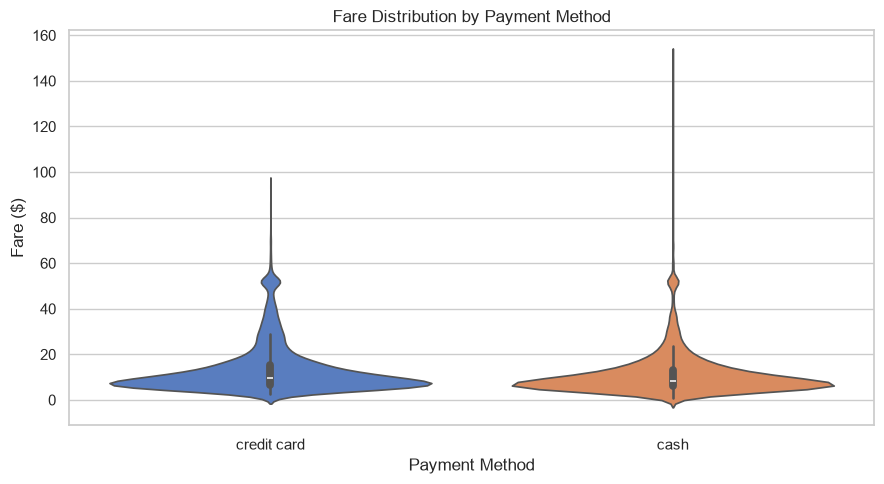

In [26]:
plt.figure(figsize=(9, 5))
sns.violinplot(
    x="payment",
    y="fare",
    data=df,
    palette="muted",
    hue="payment",
    legend=False,
)
plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare ($)")
plt.tight_layout()
plt.show()